
---
date: "2026-10-25"
date-modified: last-modified
format:
  html:
    toc: true
---


# Formulating Problems as Linear Programs

**Prerequisites:** [Linear Programs](linear-programs.ipynb)

To formulate a problem as an LP: choose real variables that describe a candidate solution, express every requirement as a linear equation or inequality in these variables, and express the cost (or gain) as a linear function of them. Often the obvious formulation is not linear, and one introduces auxiliary variables to make it linear. All examples below follow this pattern.

## 1\. The Diet Problem

::: {#exm-diet}
## Cheapest Diet Meeting Nutritional Requirements

There are $n$ foods and $m$ nutrients. One unit of food $j$ costs $c_j$ and contains $a_{ij}$ units of nutrient $i$; at least $r_i$ units of nutrient $i$ are required. Let $x_j$ be the amount of food $j$ in the diet. The cheapest diet solves
$$
\text{minimize } c^{\mathsf T}x \quad \text{subject to } Ax \ge r,\ x \ge 0,
$$
where $A = (a_{ij}) \in \mathbb{R}^{m \times n}$. The rows of $Ax \ge r$ say that each nutrient requirement is met. The constraints $x \ge 0$ are part of the problem: without them an optimal "diet" could use negative amounts of an expensive food that is poor in nutrients.
:::

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID, FAINT = "#0b0b0b", "#52514e", "#d9d8d4", "#a3a29a"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})
from scipy.optimize import linprog

# three foods, three nutrients (amount of nutrient i per kg of food j)
A = np.array([[0.4, 6.0, 0.2],     # nutrient 1
              [3.0, 2.0, 1.0],     # nutrient 2
              [1.0, 2.5, 4.0]])    # nutrient 3
r = np.array([2.0, 6.0, 8.0])      # requirements
cost = np.array([0.75, 0.50, 0.15])
res = linprog(cost, A_ub=-A, b_ub=-r, bounds=[(0, None)] * 3)
print("amounts:", res.x.round(4), " cost:", round(res.fun, 4))
print("nutrients obtained:", (A @ res.x).round(4), " required:", r)

amounts: [0.     0.1429 5.7143]  cost: 0.9286
nutrients obtained: [ 2.      6.     23.2143]  required: [2. 6. 8.]



## 2\. Maximum Flow in a Network

::: {#def-network-flow}
## Network and Flow

A **network** consists of a finite undirected graph $G = (V, E)$, a **capacity** $\kappa_e \ge 0$ for each edge $e$, and two distinct vertices, the **source** $s$ and the **sink** $t$. Fix for each edge $e = \{u, v\}$ a **reference orientation**, say from $u$ to $v$; write $e \in \operatorname{out}(u)$ and $e \in \operatorname{in}(v)$. A **flow** is a vector $f \in \mathbb{R}^E$: if $f_e \ge 0$, an amount $f_e$ flows along $e$ in the reference direction, and if $f_e < 0$ an amount $|f_e|$ flows in the opposite direction. The flow must satisfy

1. **capacity constraints:** $-\kappa_e \le f_e \le \kappa_e$ for every edge $e$;
2. **conservation:** $\sum_{e \in \operatorname{in}(v)} f_e = \sum_{e \in \operatorname{out}(v)} f_e$ for every $v \ne s, t$.

Its **value** is the net amount leaving the source, $\operatorname{val}(f) = \sum_{e \in \operatorname{out}(s)} f_e - \sum_{e \in \operatorname{in}(s)} f_e$.
:::

All constraints are linear in $f$ and so is the value. Hence a maximum flow is an optimal solution of the LP
$$
\text{maximize } \operatorname{val}(f) \quad \text{subject to 1 and 2},
$$
with one variable per edge. The reference orientation is arbitrary and is not a decision: the sign of $f_e$ in an optimal solution tells in which direction flow actually moves along $e$. Trying all $2^{|E|}$ possible directions in advance is unnecessary.

::: {.callout-note}
## An Equivalent Formulation With Two Variables per Edge
One may instead use a variable $x_{uv}$ for every ordered pair with $\{u, v\} \in E$ (the flow from $u$ to $v$) together with the linear equations $x_{uv} = -x_{vu}$. Conservation at $v$ becomes $\sum_{u : \{u,v\} \in E} x_{vu} = 0$, capacity becomes $-\kappa_e \le x_{uv} \le \kappa_e$, and the value is $\sum_{u} x_{su}$. The map $f \mapsto x$ with $x_{uv} = f_e$, $x_{vu} = -f_e$ (for $e$ oriented from $u$ to $v$) is a bijection between the two feasible sets preserving the value.
:::

::: {#prp-flow-value-at-sink}
## The Value Also Arrives at the Sink

For every flow, $\operatorname{val}(f) = \sum_{e \in \operatorname{in}(t)} f_e - \sum_{e \in \operatorname{out}(t)} f_e$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-flow-value-at-sink
For a vertex $v$ let $\operatorname{net}(v) = \sum_{e \in \operatorname{out}(v)} f_e - \sum_{e \in \operatorname{in}(v)} f_e$. Every edge $e$ is in $\operatorname{out}$ of exactly one vertex and in $\operatorname{in}$ of exactly one vertex, so $f_e$ appears once with $+$ and once with $-$ in $\sum_{v \in V}\operatorname{net}(v)$, which is therefore $0$. By conservation $\operatorname{net}(v) = 0$ for $v \ne s, t$. Hence $\operatorname{net}(s) = -\operatorname{net}(t)$, which is the claim. $\blacksquare$
:::

maximum flow value: 7.0
smallest cut capacity: (7, {'s'})


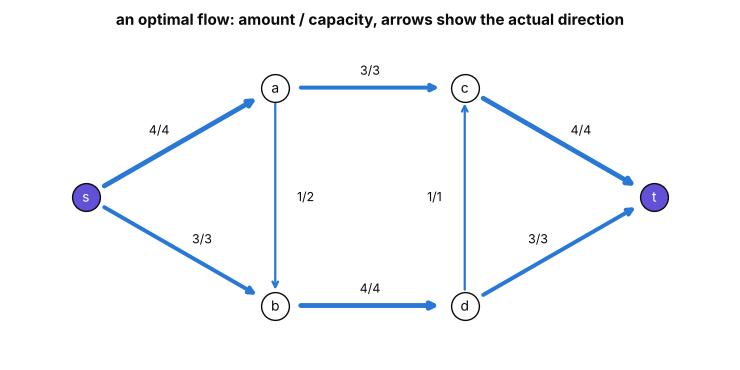

In [2]:

from itertools import combinations

V = ["s", "a", "b", "c", "d", "t"]
edges = [("s", "a", 4), ("s", "b", 3), ("a", "b", 2), ("a", "c", 3),
         ("b", "d", 4), ("c", "d", 1), ("c", "t", 4), ("d", "t", 3)]   # (tail, head, capacity)
m = len(edges)
val = np.array([(+1 if u == "s" else 0) - (1 if w == "s" else 0) for u, w, _ in edges], float)
A_eq = [[(1 if w == v else 0) - (1 if u == v else 0) for u, w, _ in edges] for v in V if v not in "st"]
res = linprog(-val, A_eq=A_eq, b_eq=np.zeros(len(A_eq)), bounds=[(-k, k) for *_, k in edges])
f = res.x
print("maximum flow value:", round(-res.fun, 6))

# compare with the smallest capacity of a cut S (s in S, t not in S)
inner = ["a", "b", "c", "d"]
cuts = []
for r in range(5):
    for extra in combinations(inner, r):
        S = {"s", *extra}
        cuts.append((sum(k for u, w, k in edges if (u in S) != (w in S)), S))
print("smallest cut capacity:", min(cuts, key=lambda z: z[0]))

pos = {"s": (0, 1), "a": (1, 2), "b": (1, 0), "c": (2, 2), "d": (2, 0), "t": (3, 1)}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for (u, w, k), fe in zip(edges, f):
    p, q = np.array(pos[u]), np.array(pos[w])
    if fe < 0:
        p, q = q, p
    ax.annotate("", xy=q - 0.12 * (q - p) / np.linalg.norm(q - p), xytext=p + 0.12 * (q - p) / np.linalg.norm(q - p),
                arrowprops=dict(arrowstyle="->", color=BLUE if abs(fe) > 1e-9 else FAINT, lw=1 + 2.5 * abs(fe) / 4))
    mid, dvec = (p + q) / 2, (q - p) / np.linalg.norm(q - p)
    ax.text(*(mid + 0.16 * np.array([-dvec[1], dvec[0]])), f"{abs(fe):.0f}/{k}", ha="center", va="center", fontsize=9, color=INK)
for v, (x, y) in pos.items():
    ax.plot(x, y, "o", ms=20, color=VIOLET if v in "st" else "white", mec=INK, zorder=3)
    ax.text(x, y, v, ha="center", va="center", color="white" if v in "st" else INK, zorder=4)
ax.set_xlim(-0.4, 3.4); ax.set_ylim(-0.5, 2.5); ax.axis("off")
ax.set_title("an optimal flow: amount / capacity, arrows show the actual direction")
plt.tight_layout(); plt.show()


The code finds the value by the LP and compares it with the smallest total capacity of edges leaving a set $S \ni s$ with $t \notin S$; the two numbers agree. (That they always agree is the max-flow min-cut theorem, which follows from LP duality.)

## 3\. Absolute Values

The function $u \mapsto |u|$ is not linear, but in a minimization with a nonnegative weight it can be replaced by linear constraints. Write $u^+ = \max(u, 0)$ and $u^- = \max(-u, 0)$, so $u = u^+ - u^-$ and $|u| = u^+ + u^-$.

::: {#lem-absolute-value}
## Two Linear Descriptions of $|u|$

Let $u \in \mathbb{R}$.

1. $\min\{p + q : p, q \ge 0,\ p - q = u\} = |u|$, attained only at $p = u^+$, $q = u^-$.
2. $\min\{e : e \ge u,\ e \ge -u\} = |u|$, attained only at $e = |u|$.
:::

::: {.callout-tip collapse="true"}
## Proof of @lem-absolute-value

1. $(u^+, u^-)$ is admissible and gives $u^+ + u^- = |u|$. If $p, q \ge 0$ and $p - q = u$, then $p \ge u$ and $p \ge 0$, so $p \ge u^+$; likewise $q = p - u \ge -u$ and $q \ge 0$, so $q \ge u^-$. Hence $p + q \ge u^+ + u^- = |u|$, with equality only if $p = u^+$ and $q = u^-$.
2. The conditions say $e \ge \max(u, -u) = |u|$. $\blacksquare$
:::

::: {#thm-absolute-value-objective}
## Minimizing Weighted Sums of Absolute Values

Let $P \subseteq \mathbb{R}^n$ be described by linear constraints, let $w_1, \dots, w_k \ge 0$, and let $\ell_1, \dots, \ell_k$ be affine functions $\ell_j(x) = \alpha_j^{\mathsf T}x - \beta_j$. Consider
$$
(\mathrm N)\quad \text{minimize } F(x) = c^{\mathsf T}x + \sum_{j=1}^k w_j\,|\ell_j(x)| \ \text{ over } x \in P,
$$
$$
(\mathrm L)\quad \text{minimize } c^{\mathsf T}x + \sum_{j=1}^k w_j e_j \ \text{ subject to } x \in P,\ e_j \ge \ell_j(x),\ e_j \ge -\ell_j(x)\ (j = 1, \dots, k).
$$
(L) is an LP in the variables $(x, e)$. For every feasible $(x, e)$ of (L) its objective value is $\ge F(x)$, and for every $x \in P$ the choice $e_j = |\ell_j(x)|$ gives equality. Consequently both problems have the same infimum, $x^*$ is optimal for (N) if and only if $(x^*, (|\ell_j(x^*)|)_j)$ is optimal for (L), and the $x$-part of every optimal solution of (L) is optimal for (N).

The same holds if $|\ell_j(x)|$ is replaced by $p_j + q_j$ with constraints $p_j - q_j = \ell_j(x)$, $p_j, q_j \ge 0$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-absolute-value-objective
If $(x, e)$ is feasible for (L), then $e_j \ge |\ell_j(x)|$ by @lem-absolute-value(2), and since $w_j \ge 0$, $c^{\mathsf T}x + \sum w_j e_j \ge F(x)$. For $x \in P$, $(x, (|\ell_j(x)|)_j)$ is feasible for (L) with value exactly $F(x)$. So the set of values of (L) contains the set of values of (N), and every value of (L) is bounded below by a value of (N); hence the infima coincide.

If $x^*$ is optimal for (N) and $(x, e)$ is feasible for (L), then the value of $(x, e)$ is $\ge F(x) \ge F(x^*)$, which is the value of $(x^*, |\ell(x^*)|)$; so this pair is optimal for (L). If $(x^*, e^*)$ is optimal for (L) and $x \in P$, then $F(x^*) \le$ value of $(x^*, e^*) \le$ value of $(x, |\ell(x)|) = F(x)$; so $x^*$ is optimal for (N). For the second description use @lem-absolute-value(1) in the same way. $\blacksquare$
:::

::: {.callout-warning}
## The Direction of Optimization Matters
The trick needs a *minimization* with weights $w_j \ge 0$: then the optimizer pushes each $e_j$ down to $|\ell_j(x)|$. To *maximize* $\sum |\ell_j(x)|$ it fails, since $e_j$ can be made arbitrarily large while $e_j \ge \pm\ell_j(x)$ stays true; the LP is then unbounded whatever the original problem is.
:::

## 4\. Production Planning With Smoothing

::: {#exm-production-planning}
## Production Plan With Storage and Change Costs

The demand in months $1, \dots, T$ is known: $d_1, \dots, d_T \ge 0$, and all of it must be met. Production in month $i$ is $x_i \ge 0$; production in the previous month was $x_0$ (given). Surplus is stored: let $s_i$ be the stock at the end of month $i$, with $s_0 = 0$. Storing one unit for one month costs $\alpha > 0$, and changing production by one unit between consecutive months costs $\beta > 0$ (up or down). The problem is
$$
\begin{aligned}
\text{minimize } \ & \alpha\sum_{i=1}^T s_i + \beta \sum_{i=1}^T |x_i - x_{i-1}| \\
\text{subject to } \ & s_i = s_{i-1} + x_i - d_i,\quad s_i \ge 0,\quad x_i \ge 0 \qquad (i = 1, \dots, T).
\end{aligned}
$$
The requirement "all demand is met", $s_{i-1} + x_i \ge d_i$, is the same as $s_i \ge 0$ by the first equation, so it need not be written separately.

By @thm-absolute-value-objective, this is equivalent to the LP
$$
\begin{aligned}
\text{minimize } \ & \alpha\sum_{i=1}^T s_i + \beta\sum_{i=1}^T (y_i + z_i) \\
\text{subject to } \ & s_i = s_{i-1} + x_i - d_i,\quad x_i - x_{i-1} = y_i - z_i,\quad s_i, x_i, y_i, z_i \ge 0,
\end{aligned}
$$
where at an optimum $y_i$ is the increase and $z_i$ the decrease of production in month $i$.
:::

::: {.callout-warning}
## Stock Left at the End
Nothing forces $s_T = 0$. Lowering the last month's production removes leftover stock but can increase $|x_T - x_{T-1}|$, so an optimal plan may end with positive stock (the plan computed below does). If the stock must be empty at the end, add the constraint $s_T = 0$.
:::

optimal cost: 720.0 | final stock: 10.0
with s_T = 0 required: 740.0


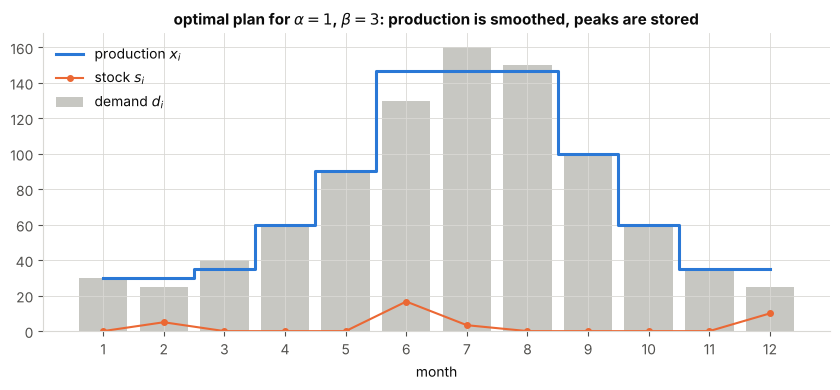

In [3]:

def plan(d, x0, alpha, beta, end_empty=False):
    """Solve the production LP; variables are x, s, y, z (each of length T)."""
    T = len(d); N = 4 * T
    X, S, Y, Z = (np.arange(T) + k * T for k in range(4))
    cost = np.r_[np.zeros(T), alpha * np.ones(T), beta * np.ones(2 * T)]
    rows, rhs = [], []
    for i in range(T):
        r1 = np.zeros(N); r1[S[i]] = 1; r1[X[i]] = -1
        if i > 0: r1[S[i - 1]] = -1
        rows.append(r1); rhs.append(-d[i])                  # s_i - s_{i-1} - x_i = -d_i
        r2 = np.zeros(N); r2[X[i]] = 1; r2[Y[i]] = -1; r2[Z[i]] = 1
        if i > 0: r2[X[i - 1]] = -1
        rows.append(r2); rhs.append(x0 if i == 0 else 0)    # x_i - x_{i-1} - y_i + z_i = 0
    if end_empty:
        r3 = np.zeros(N); r3[S[-1]] = 1; rows.append(r3); rhs.append(0)
    res = linprog(cost, A_eq=np.array(rows), b_eq=rhs, bounds=[(0, None)] * N)
    return res.fun, res.x[X], res.x[S]

d = np.array([30, 25, 40, 60, 90, 130, 160, 150, 100, 60, 35, 25], float)
total, x, s = plan(d, x0=30, alpha=1, beta=3)
total0, x0_, s0_ = plan(d, x0=30, alpha=1, beta=3, end_empty=True)
print("optimal cost:", round(total, 3), "| final stock:", round(s[-1], 3))
print("with s_T = 0 required:", round(total0, 3))

months = np.arange(1, 13)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.bar(months, d, color=FAINT, alpha=0.6, label="demand $d_i$")
ax.step(months, x, where="mid", color=BLUE, lw=2.2, label="production $x_i$")
ax.plot(months, s, "o-", color=ORANGE, ms=4, label="stock $s_i$")
ax.set_xticks(months); ax.set_xlabel("month"); ax.legend(loc="upper left")
ax.set_title(r"optimal plan for $\alpha = 1$, $\beta = 3$: production is smoothed, peaks are stored")
plt.tight_layout(); plt.show()


## 5\. Fitting a Line

Given points $(x_1, y_1), \dots, (x_N, y_N)$, the **residuals** of the line $y = ax + b$ are $y_i - ax_i - b$.

::: {#prp-least-squares-line}
## The Least Squares Line

Assume the $x_i$ are not all equal. Let $\bar x, \bar y$ be the means, $S_{xx} = \sum (x_i - \bar x)^2$ and $S_{xy} = \sum (x_i - \bar x)(y_i - \bar y)$. Then $g(a, b) = \sum_i (y_i - ax_i - b)^2$ has the unique minimizer
$$
a = \frac{S_{xy}}{S_{xx}}, \qquad b = \bar y - a\bar x .
$$
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-least-squares-line
Write $y_i - ax_i - b = \big((y_i - \bar y) - a(x_i - \bar x)\big) + (\bar y - a\bar x - b)$. Since $\sum (y_i - \bar y) = \sum (x_i - \bar x) = 0$, the cross term vanishes after summing:
$$
g(a, b) = \sum_i \big((y_i - \bar y) - a(x_i - \bar x)\big)^2 + N(\bar y - a\bar x - b)^2 = S_{yy} - 2aS_{xy} + a^2S_{xx} + N(\bar y - a\bar x - b)^2,
$$
with $S_{yy} = \sum (y_i - \bar y)^2$. The last term is $\ge 0$ with equality only for $b = \bar y - a\bar x$. The quadratic $S_{yy} - 2aS_{xy} + a^2 S_{xx} = S_{xx}\big(a - \frac{S_{xy}}{S_{xx}}\big)^2 + S_{yy} - \frac{S_{xy}^2}{S_{xx}}$ (with $S_{xx} > 0$) is minimal only at $a = S_{xy}/S_{xx}$. $\blacksquare$
:::

The least squares line is found by solving linear equations; no LP is needed. Minimizing the sum of the *absolute* residuals is a different problem, and it is an LP.

::: {#exm-l1-line}
## The Least Absolute Deviations Line

By @thm-absolute-value-objective, minimizing $\sum_i |y_i - ax_i - b|$ over $(a, b) \in \mathbb{R}^2$ is equivalent to the LP in the variables $(a, b, e_1, \dots, e_N)$:
$$
\text{minimize } e_1 + \dots + e_N \quad \text{subject to } e_i \ge y_i - ax_i - b,\ \ e_i \ge -(y_i - ax_i - b) \quad (i = 1, \dots, N).
$$
The objective vector is $(0, 0, 1, \dots, 1)$: variables may have coefficient $0$ in the objective.
:::

::: {.callout-note}
## Intuition: Squares Exaggerate Large Residuals
A residual of size $10$ contributes $100$ to the sum of squares but only $10$ to the sum of absolute values. So one far-off point (an outlier) pulls the least squares line much more strongly than the least absolute deviations line, as the figure shows.
:::

least squares:        a = 0.937, b = 0.024
least abs deviations: a = 0.606, b = 0.796  (sum |r_i| = 13.950)


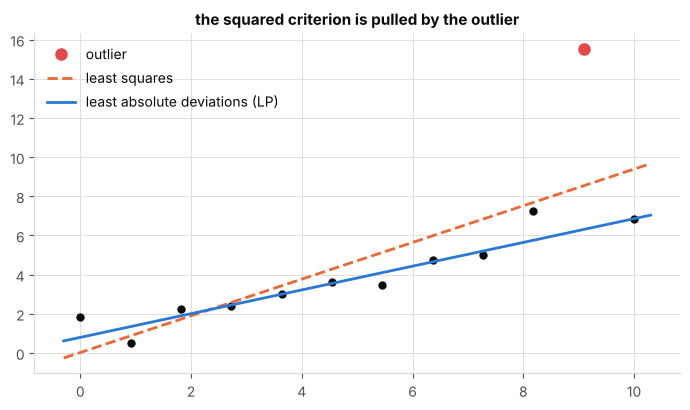

In [4]:

rng = np.random.default_rng(3)
xs = np.linspace(0, 10, 12)
ys = 0.6 * xs + 1 + rng.normal(0, 0.4, xs.size)
ys[-2] += 9                                     # one outlier
N = xs.size

a2 = np.sum((xs - xs.mean()) * (ys - ys.mean())) / np.sum((xs - xs.mean()) ** 2)
b2 = ys.mean() - a2 * xs.mean()

# LP: variables (a, b, e_1..e_N); constraints  -a x_i - b - e_i <= -y_i  and  a x_i + b - e_i <= y_i
A_ub = np.vstack([np.c_[-xs, -np.ones(N), -np.eye(N)], np.c_[xs, np.ones(N), -np.eye(N)]])
b_ub = np.r_[-ys, ys]
res = linprog(np.r_[0, 0, np.ones(N)], A_ub=A_ub, b_ub=b_ub, bounds=[(None, None)] * 2 + [(0, None)] * N)
a1, b1 = res.x[:2]
print(f"least squares:        a = {a2:.3f}, b = {b2:.3f}")
print(f"least abs deviations: a = {a1:.3f}, b = {b1:.3f}  (sum |r_i| = {res.fun:.3f})")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(xs, ys, "o", color=INK, ms=5)
ax.plot(xs[-2], ys[-2], "o", color=RED, ms=8, label="outlier")
t = np.linspace(-0.3, 10.3, 2)
ax.plot(t, a2 * t + b2, color=ORANGE, lw=2, ls="--", label="least squares")
ax.plot(t, a1 * t + b1, color=BLUE, lw=2, label="least absolute deviations (LP)")
ax.legend(loc="upper left"); ax.set_title("the squared criterion is pulled by the outlier")
plt.tight_layout(); plt.show()


## 6\. Separating Two Point Sets

::: {#exm-separating-line}
## A Line Separating Two Finite Sets

Let $P, Q \subset \mathbb{R}^2$ be finite. We look for a line $y = ax + b$ with every point of $P$ strictly above it and every point of $Q$ strictly below it. Writing $(x_p, y_p)$ for the coordinates of $p$, consider the LP in the variables $(a, b, \delta)$:
$$
\text{maximize } \delta \quad \text{subject to } y_p \ge ax_p + b + \delta\ \ (p \in P), \qquad y_q \le ax_q + b - \delta\ \ (q \in Q).
$$
The data $x_p, y_p$ are numbers, so each constraint is linear in $(a, b, \delta)$. Then: *a separating non-vertical line exists if and only if the LP has a feasible solution with $\delta > 0$*, that is, iff its optimal value is positive or it is unbounded. For a feasible $(a, b, \delta)$ with $\delta > 0$, the strip of vertical half-width $\delta$ around the line contains no point of $P \cup Q$, so maximizing $\delta$ looks for a line with a wide empty strip.
:::

::: {.callout-tip collapse="true"}
## Proof of the claim in @exm-separating-line
If $(a, b, \delta)$ is feasible with $\delta > 0$, then $y_p \ge ax_p + b + \delta > ax_p + b$ and $y_q \le ax_q + b - \delta < ax_q + b$, so $y = ax + b$ separates. Conversely, if $y = ax + b$ separates strictly, let $\delta = \min\big(\min_{p}(y_p - ax_p - b),\ \min_q (ax_q + b - y_q)\big)$; this is a minimum of finitely many positive numbers, so $\delta > 0$, and $(a, b, \delta)$ is feasible. $\blacksquare$
:::

::: {.callout-warning}
## Strict Inequalities and Unbounded Margins
LPs use only non-strict inequalities ($\le$, $\ge$); the variable $\delta$ turns the strict requirements into non-strict ones. The vertical margin can be unbounded: for $P = \{(0, 0)\}$, $Q = \{(1, 0)\}$ the lines $y = ax - a/2$ with $a \to \infty$ are feasible with $\delta = a/2$. Then every feasible solution with $\delta > 0$ still gives a separating line; to obtain a meaningful widest strip add bounds such as $-M \le a \le M$.
:::

::: {#exm-separating-curve}
## Separating by a Polynomial Curve

To separate by the graph of $y = a_0 + a_1x + \dots + a_dx^d$, use the constraints $y_p \ge \sum_k a_k x_p^k + \delta$ and $y_q \le \sum_k a_k x_q^k - \delta$. The powers $x_p^k$ are numbers computed from the data, so the constraints are linear in the unknowns $(a_0, \dots, a_d, \delta)$. "Linear" refers to the variables, not to the shape of the curve.
:::

degree 1: best margin delta = -0.959 (no separation)
degree 2: best margin delta = 0.342 (separates)


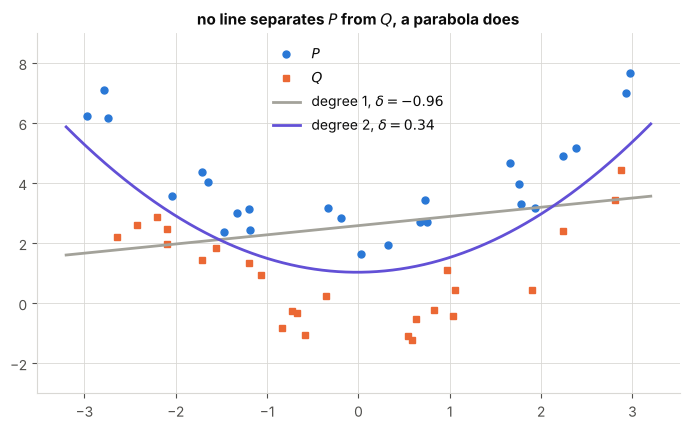

In [5]:

rng = np.random.default_rng(7)
Px = rng.uniform(-3, 3, 25); Py = 0.5 * Px**2 + 1.0 + rng.uniform(0.3, 2.5, 25)   # above a parabola
Qx = rng.uniform(-3, 3, 25); Qy = 0.5 * Qx**2 + 1.0 - rng.uniform(0.3, 2.5, 25)   # below it

def separate(deg, M=50):
    """maximize delta for a polynomial of degree deg; coefficients bounded by M."""
    VP = np.vander(Px, deg + 1, increasing=True); VQ = np.vander(Qx, deg + 1, increasing=True)
    A_ub = np.vstack([np.c_[VP, np.ones(len(Px))], np.c_[-VQ, np.ones(len(Qx))]])
    b_ub = np.r_[Py, -Qy]
    c = np.r_[np.zeros(deg + 1), -1.0]
    return linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=[(-M, M)] * (deg + 1) + [(None, None)])

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(Px, Py, "o", color=BLUE, ms=5, label="$P$")
ax.plot(Qx, Qy, "s", color=ORANGE, ms=5, label="$Q$")
t = np.linspace(-3.2, 3.2, 300)
for deg, col in [(1, FAINT), (2, VIOLET)]:
    r = separate(deg)
    delta = -r.fun
    coef = r.x[:-1]
    print(f"degree {deg}: best margin delta = {delta:.3f}", "(separates)" if delta > 0 else "(no separation)")
    ax.plot(t, np.polyval(coef[::-1], t), color=col, lw=2, label=f"degree {deg}, $\\delta = {delta:.2f}$")
ax.legend(loc="upper center"); ax.set_ylim(-3, 9)
ax.set_title("no line separates $P$ from $Q$, a parabola does")
plt.tight_layout(); plt.show()


## 7\. The Largest Disc in a Convex Polygon

::: {#lem-ball-in-halfspace}
## A Ball Inside a Half-Plane

Let $a \ne 0$, $z \in \mathbb{R}^n$, $r \ge 0$. The closed ball $B(z, r) = \{x : \lVert x - z\rVert \le r\}$ lies in $\{x : a^{\mathsf T}x \le \beta\}$ if and only if $a^{\mathsf T}z + r\lVert a\rVert \le \beta$.
:::

::: {.callout-tip collapse="true"}
## Proof of @lem-ball-in-halfspace
For $x = z + h$ with $\lVert h\rVert \le r$, the [Cauchy–Schwarz inequality](Cauchy-Schwarz-inequality.ipynb) gives $a^{\mathsf T}x = a^{\mathsf T}z + a^{\mathsf T}h \le a^{\mathsf T}z + r\lVert a\rVert$, with equality for $h = r\,a/\lVert a\rVert$. So $\max_{x \in B(z,r)} a^{\mathsf T}x = a^{\mathsf T}z + r\lVert a\rVert$, and the ball lies in the half-plane iff this maximum is $\le \beta$. $\blacksquare$
:::

::: {#exm-largest-disc}
## The Largest Inscribed Disc Is an LP

Let $P = \{x \in \mathbb{R}^2 : a_i^{\mathsf T}x \le b_i,\ i = 1, \dots, m\}$ with all $a_i \ne 0$. By @lem-ball-in-halfspace, $B(z, r) \subseteq P$ iff $a_i^{\mathsf T}z + r\lVert a_i\rVert \le b_i$ for all $i$. The numbers $\lVert a_i\rVert$ are data, so the largest disc in $P$ is found from the LP in $(z_1, z_2, r)$:
$$
\text{maximize } r \quad \text{subject to } a_i^{\mathsf T}z + \lVert a_i\rVert\, r \le b_i\ \ (i = 1, \dots, m), \quad r \ge 0 .
$$
For the smallest disc *containing* a polygon with corners $v_j$, the conditions $\lVert v_j - z\rVert \le r$ are not linear in $(z, r)$, and this method does not apply.
:::

center: [3.5932 2.394 ]  radius: 2.394
distances of the center to the edge lines: [2.394  3.0403 2.394  2.394  3.2685]


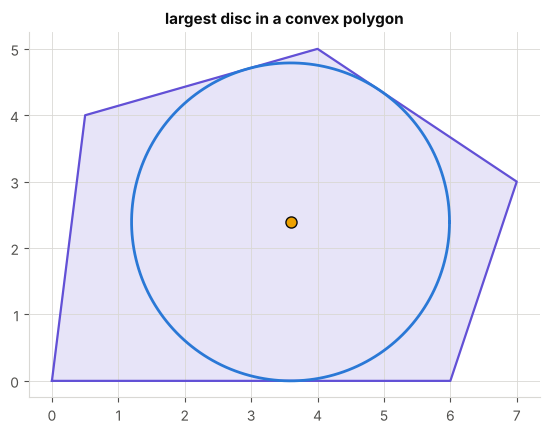

In [6]:

verts = np.array([[0, 0], [6, 0], [7, 3], [4, 5], [0.5, 4]], float)
k = len(verts)
A_p, b_p = [], []
for i in range(k):                       # edge from v_i to v_{i+1}; polygon is counterclockwise
    p, q = verts[i], verts[(i + 1) % k]
    nrm = np.array([q[1] - p[1], p[0] - q[0]])   # outward normal
    A_p.append(nrm); b_p.append(nrm @ p)
A_p, b_p = np.array(A_p), np.array(b_p)
res = linprog([0, 0, -1], A_ub=np.c_[A_p, np.linalg.norm(A_p, axis=1)], b_ub=b_p,
              bounds=[(None, None), (None, None), (0, None)])
z, r = res.x[:2], res.x[2]
print("center:", z.round(4), " radius:", round(r, 4))
print("distances of the center to the edge lines:", ((b_p - A_p @ z) / np.linalg.norm(A_p, axis=1)).round(4))

fig, ax = plt.subplots(figsize=(5.6, 4.4))
ax.fill(*verts.T, color=VIOLET, alpha=0.15); ax.plot(*np.vstack([verts, verts[:1]]).T, color=VIOLET, lw=1.6)
th = np.linspace(0, 2 * np.pi, 200)
ax.plot(z[0] + r * np.cos(th), z[1] + r * np.sin(th), color=BLUE, lw=2)
ax.plot(*z, "o", color=YELLOW, mec=INK, ms=8)
ax.set_aspect("equal"); ax.set_title("largest disc in a convex polygon")
plt.tight_layout(); plt.show()


The printout shows the inscribed disc touching three of the edge lines (distance equal to $r$).

## 8\. Cutting Paper Rolls

::: {#exm-cutting-stock}
## The Cutting Stock Problem

Rolls of width $300$ are available in any number. We need $97$ rolls of width $135$, $610$ of width $108$, $395$ of width $93$, and $211$ of width $42$ (all of the same length). How few rolls of width $300$ suffice?

A **cutting pattern** is a vector $p = (p_1, p_2, p_3, p_4)$ of nonnegative integers with $135p_1 + 108p_2 + 93p_3 + 42p_4 \le 300$: one roll is cut into $p_1$ pieces of width $135$, and so on. Call it **maximal** if the waste is $< 42$, so that no further piece fits. Any pattern can be enlarged to a maximal one by adding pieces, and extra pieces do no harm, so only maximal patterns are needed. There are $12$ of them (computed below); call them $p^{(1)}, \dots, p^{(12)}$. With $x_j$ = the number of rolls cut by pattern $j$, the problem is
$$
\text{minimize } \sum_{j=1}^{12} x_j \quad \text{subject to } \sum_{j=1}^{12} p^{(j)}_i x_j \ge d_i\ \ (i = 1, \dots, 4), \quad x_j \ge 0,\ \ x_j \in \mathbb{Z},
$$
with $d = (97, 610, 395, 211)$. Without the condition $x_j \in \mathbb{Z}$ this is an LP. Its optimal value is $452.25$.

- Every integer solution is a solution of the LP, so every integer solution uses at least $452.25$, hence at least $453$ rolls.
- Rounding every $x_j$ of an LP optimum up to an integer keeps all constraints (the coefficients $p^{(j)}_i$ are $\ge 0$) and increases $\sum x_j$ by less than the number of patterns used fractionally (at most $12$). Here it gives $453$ rolls.

So $453$ rolls are optimal. Problems with the condition $x \in \mathbb{Z}^n$ are [integer programs](integer-programming.ipynb).
:::

In [7]:

from itertools import product

W, widths, demand = 300, np.array([135, 108, 93, 42]), np.array([97, 610, 395, 211])
patterns = [p for p in product(*(range(W // w + 1) for w in widths))
            if (used := np.dot(p, widths)) <= W and W - used < widths.min()]
Pm = np.array(patterns).T                       # column j = pattern j
print(len(patterns), "maximal patterns (pieces of 135, 108, 93, 42 | waste):")
for p in patterns:
    print("  ", p, "|", W - np.dot(p, widths))
res = linprog(np.ones(len(patterns)), A_ub=-Pm, b_ub=-demand, bounds=[(0, None)] * len(patterns))
x_up = np.ceil(res.x - 1e-9)
print("LP optimum:", round(res.fun, 4), "| rounded up:", int(x_up.sum()), "rolls, producing", Pm @ x_up.astype(int))

12 maximal patterns (pieces of 135, 108, 93, 42 | waste):
   (0, 0, 0, 7) | 6
   (0, 0, 1, 4) | 39
   (0, 0, 2, 2) | 30
   (0, 0, 3, 0) | 21
   (0, 1, 0, 4) | 24
   (0, 1, 1, 2) | 15
   (0, 1, 2, 0) | 6
   (0, 2, 0, 2) | 0
   (1, 0, 0, 3) | 39
   (1, 0, 1, 1) | 30
   (1, 1, 0, 1) | 15
   (2, 0, 0, 0) | 30
LP optimum: 452.25 | rounded up: 453 rolls, producing [ 97 611 396 413]
